# Assignment 1 · Part 3 — Camera models
## 25 points

Fitting a body model to a photograph requires predicting the photograph: given a 3D scene and a camera, where does each point land in the image? This part implements the camera model of the lecture,
examines the distortion of shapes under perspective, finds the pose of an object that produces a prescribed image, and changes the camera intrinsics instead of the object (Lecture 02.1, slides 42–80; focal length versus viewpoint: slides 36–39).

*Optional: the interactive companion `assignment_1_lab.html` (open it in a browser; tabs "Camera") visualises the concepts of this part. Nothing in this notebook depends on it.*

### Instructions

Complete the code between `START OF YOUR SOLUTION` and `END OF YOUR SOLUTION` (replace every `None`) and answer the written questions in the cells headed **Answer**.
A check cell follows each coding block; it compares your functions with reference values and is meant as a self-test — grading is based on your code and your written answers.
Inside formulas angles are in radians (`np.deg2rad` converts degrees); rotations are counter-clockwise. Submit the notebook together with a PDF export, one submission per team.

### Notation used in this part

| Symbol | Meaning |
|---|---|
| $\mathbf{p}_W=(U,V,W)^\top$ | a point in **world** coordinates ($W$ points up) |
| $\mathbf{C}$ | the camera centre in world coordinates |
| $\mathbf{R}$ | **extrinsic** rotation, from world to camera coordinates (the transpose of the matrix whose columns are the camera axes). The three **rows** of $\mathbf{R}$ are the camera axes $X$ (right), $Y$ (down), $Z$ (forward) written in world coordinates (slides 66–68) |
| $\mathbf{p}_C=(X,Y,Z)^\top=\mathbf{R}(\mathbf{p}_W-\mathbf{C})$ | the point in **camera** coordinates (slide 58) |
| $f$ | focal length (a **length** in the units of the scene; here $f=1$, so $f/s_x=400$ px). $(x,y)=\bigl(f\tfrac{X}{Z},\,f\tfrac{Y}{Z}\bigr)$ are the **film** coordinates (slide 51) |
| $s_x,s_y$ | pixel size (length per pixel; the \"effective scale factors\" of slide 76). $(o_x,o_y)$ is the **principal point** in pixels |
| $(u,v)$ | **pixel** coordinates; $u$ points right, $v$ points **down** |
| $u=\dfrac{f}{s_x}\dfrac{X}{Z}+o_x,\quad v=\dfrac{f}{s_y}\dfrac{Y}{Z}+o_y$ | perspective projection with intrinsics (slides 76–77) |
| $\mathbf{K}=\begin{bmatrix}f/s_x&0&o_x\\0&f/s_y&o_y\\0&0&1\end{bmatrix}$ | intrinsic matrix, so that $\ \lambda\,(u,v,1)^\top=\mathbf{K}\,\mathbf{p}_C$ with $\lambda=Z$ |
| $\mathbf{Q}$ | a rotation of the camera *body*, expressed in the camera frame. The camera axes rotate with it: $\mathbf{R}'=\mathbf{Q}^\top\mathbf{R}$ (because the rows of $\mathbf{R}$ are the axes) |

In [32]:
#@title Setup — run this cell first
import os, sys, zipfile

# The helper package `vh_a1` (plots, given functions, self-checks) ships as vh_a1.zip next to this notebook.
if not os.path.isdir("vh_a1"):
    if not os.path.exists("vh_a1.zip") and "google.colab" in sys.modules:
        from google.colab import files
        print("Select the file vh_a1.zip (part of the assignment material):")
        uploaded = files.upload()
        if uploaded:
            os.replace(next(iter(uploaded)), "vh_a1.zip")
    if not os.path.exists("vh_a1.zip"):
        raise RuntimeError("Package not found: put the folder vh_a1/ or the file vh_a1.zip next to this notebook and run this cell again.")
    zipfile.ZipFile("vh_a1.zip").extractall(".")

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from vh_a1 import params
from vh_a1.common import Checker, progress, ready
np.set_printoptions(precision=4, suppress=True)

In [33]:
from vh_a1 import part3 as G
from vh_a1.part3 import (intrinsics, rigid, depth, draw_image, draw_scene, cube_vertices,
                         Rx, Ry, Rz, RECT1, RECT2)

W_img, H_img = params.P3_IMAGE                      # image size in pixels
f, (s_x, s_y) = params.P3_F, params.P3_S            # focal length and pixel size
o = np.array(params.P3_O)                           # principal point (o_x, o_y) in pixels
C = np.array(params.P3_C)                           # camera centre
R = np.array(params.P3_R)                           # extrinsic rotation: rows = camera X, Y, Z axes in world coordinates
K = intrinsics(f, s_x, s_y, *o)                     # intrinsic matrix
print("K =\n", K, "\nR =\n", R, "\nC =", C)

K =
 [[400.   0. 220.]
 [  0. 400. 160.]
 [  0.   0.   1.]] 
R =
 [[ 1.  0.  0.]
 [ 0.  0. -1.]
 [ 0.  1.  0.]] 
C = [ 2.  -6.   1.5]


The scene below is seen from above (the $U$–$V$ plane); the camera looks along $+V$. Two rectangles and a cube are given; the image they produce is computed in Task 3.1.

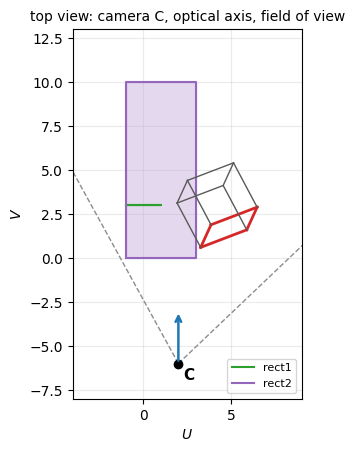

In [34]:
G.draw_topview({"rect1": RECT1, "rect2": RECT2}, R, C, K, cube=cube_vertices(), title="top view: camera C, optical axis, field of view")
plt.show()

## Task 3.1 · Getting familiar with camera pose and projection (5 points)

**(a) The projection (2 points).** Implement `project(K, R, C, p_W)`: the pixel $(u,v)$ of the world point $\mathbf{p}_W$,
$$\mathbf{p}_C=\mathbf{R}(\mathbf{p}_W-\mathbf{C}),\qquad \begin{bmatrix}\lambda u\\ \lambda v\\ \lambda\end{bmatrix}=\mathbf{K}\,\mathbf{p}_C,\qquad (u,v)=\Bigl(\tfrac{\lambda u}{\lambda},\tfrac{\lambda v}{\lambda}\Bigr). \tag{1}$$
(Assume the point is in front of the camera, $Z>0$.)

In [35]:
#### START OF YOUR SOLUTION ####
def project(K, R, C, p_W):
    """Eq. (1): pixel (u, v) of the world point p_W, returned as an array of shape (2,)."""
    p_c = R @ (p_W - C)
    p_s = K @ p_c
    return p_s[:2] / p_s[-1]
#### END OF YOUR SOLUTION ####

In [36]:
chk = Checker("Part 3 · Task 3.1a project")
pts = np.array([[2.0, 3.0, 1.5], [1.0, 1.0, 2.0], [3.5, 4.0, 0.5], [-1.0, 6.0, 0.0]])
chk.close("a point on the optical axis lands on the principal point", lambda: project(K, R, C, C + 7.0 * R[2]), o, atol=1e-9)
for i, p in enumerate(pts):
    chk.close(f"project(p_{i + 1}), p = {p}", lambda p=p: project(K, R, C, p), [[220.0, 160.0], [162.857143, 131.428571], [280.0, 200.0], [120.0, 210.0]][i], atol=1e-4,
              hint="p_C = R (p_W − C);  then divide the first two components of K p_C by the third (λ = Z)")

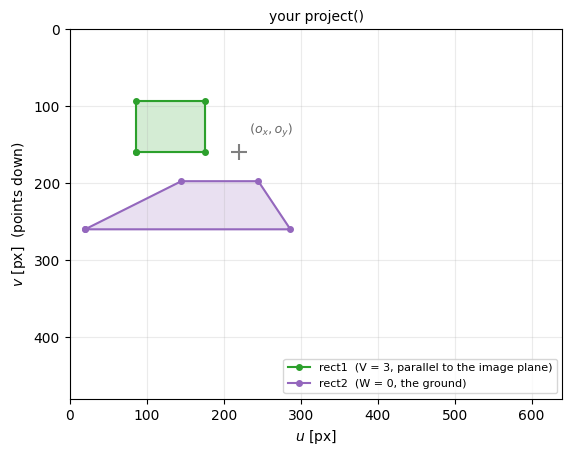

In [37]:
draw_image({"rect1  (V = 3, parallel to the image plane)": RECT1, "rect2  (W = 0, the ground)": RECT2}, project, K, R, C, title="your project()")
plt.show()

In [38]:
RECT1

array([[-1. ,  3. ,  1.5],
       [-1. ,  3. ,  3. ],
       [ 1. ,  3. ,  3. ],
       [ 1. ,  3. ,  1.5]])

**(b) A third rectangle (1 point).** Define `rect3`: a rectangle of size $3\times2$ in the plane $U=\text{const}$ (parallel to the $V$–$W$ plane, like a wall): **3 long along $V$, 2 along $W$**,
given by its four corners (array of shape $(4,3)$, in order around the rectangle) and **completely visible** in the image.
Compare the three projected shapes in your plot: which remain rectangles, which edges stay parallel?

In [39]:
#### START OF YOUR SOLUTION ####
rect3 = np.array([[1, -2,  -1], [1, 1, -1], [1, 1, 1], [1, -2, 1]])
#### END OF YOUR SOLUTION ####

In [40]:
chk = Checker("Part 3 · Task 3.1b rect3")
def _in_view(P_):
    uv = np.array([project(K, R, C, p) for p in P_]); z = [depth(R, C, p) for p in P_]
    return bool(np.all(np.array(z) > 0) and np.all((uv[:, 0] >= 0) & (uv[:, 0] <= W_img) & (uv[:, 1] >= 0) & (uv[:, 1] <= H_img)))
chk.test("rect3 has four corners with the same U (a wall parallel to the V-W plane)", lambda: None if rect3 is None else bool(np.shape(rect3) == (4, 3) and np.ptp(np.asarray(rect3)[:, 0]) < 1e-9))
chk.test("its extent is 3 along V and 2 along W", lambda: None if rect3 is None else bool(np.allclose([np.ptp(np.asarray(rect3)[:, 1]), np.ptp(np.asarray(rect3)[:, 2])], [3, 2])))
chk.test("it is a rectangle (right angles at the corners)", lambda: None if rect3 is None else bool(all(abs((np.asarray(rect3)[(i + 1) % 4] - np.asarray(rect3)[i]) @ (np.asarray(rect3)[(i + 2) % 4] - np.asarray(rect3)[(i + 1) % 4])) < 1e-9 for i in range(4))))
chk.test("all four corners are in front of the camera and inside the image", lambda: None if rect3 is None else _in_view(np.asarray(rect3)),
         hint="try U between −1 and 3.5 and V between 0 and 10")

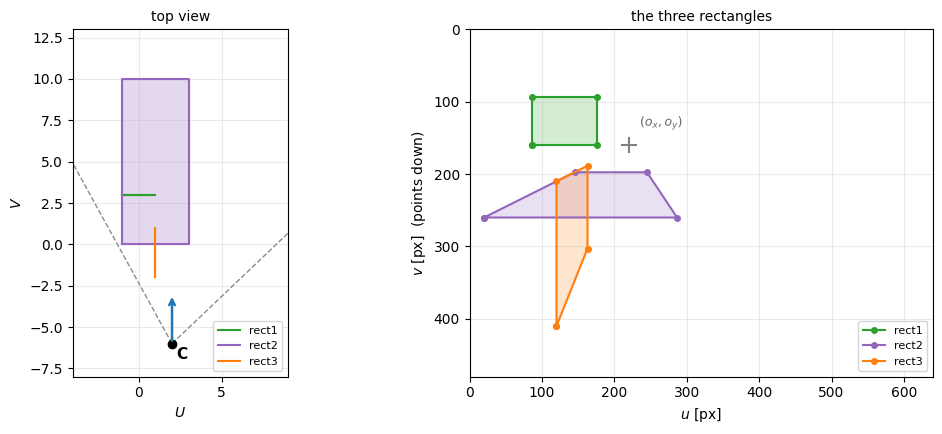

In [41]:
if ready(rect3):
    draw_scene({"rect1": RECT1, "rect2": RECT2, "rect3": rect3}, project, K, R, C, title="the three rectangles")

**(c) Moving the camera (2 points).**
* Rotate the camera **body** by $20^\circ$ about its **own $X$ axis** ($\mathbf{Q}=\mathbf{R}_x(20^\circ)$) and store the new extrinsic rotation in `R_tilt`.
* Translate the camera by $+3$ units along the world $U$ axis and store the new camera centre in `C_shift`.

(Everything else stays the same.) Describe what happens to the image in each case.

In [42]:
C

array([ 2. , -6. ,  1.5])

In [43]:
#### START OF YOUR SOLUTION ####
R_tilt  = np.array([[1, 0, 0 ], [0, np.cos(np.deg2rad(20)), np.sin(np.deg2rad(20))], [0, -np.sin(np.deg2rad(20)), np.cos(np.deg2rad(20))]]) @ R        # TODO: new extrinsic rotation after turning the camera body by Q = R_x(20°)
C_shift = np.array([3, 0, 0]) + C
#### END OF YOUR SOLUTION ####

In [44]:
chk = Checker("Part 3 · Task 3.1c moving the camera")
chk.test("R_tilt is a rotation matrix", lambda: None if R_tilt is None else bool(np.allclose(np.asarray(R_tilt) @ np.asarray(R_tilt).T, np.eye(3)) and np.linalg.det(R_tilt) > 0))
chk.close("R_tilt R^T = R_x(20°)^T  (body rotated by Q = R_x(20°); R' = Q^T R)", lambda: None if R_tilt is None else np.asarray(R_tilt) @ R.T, [[1.0, 0.0, 0.0], [0.0, 0.939693, 0.34202], [0.0, -0.34202, 0.939693]], atol=1e-6,
          hint="R' = Qᵀ R — the rows of R are the camera axes and they rotate with the body")
chk.close("C_shift", lambda: C_shift, [5.0, -6.0, 1.5])

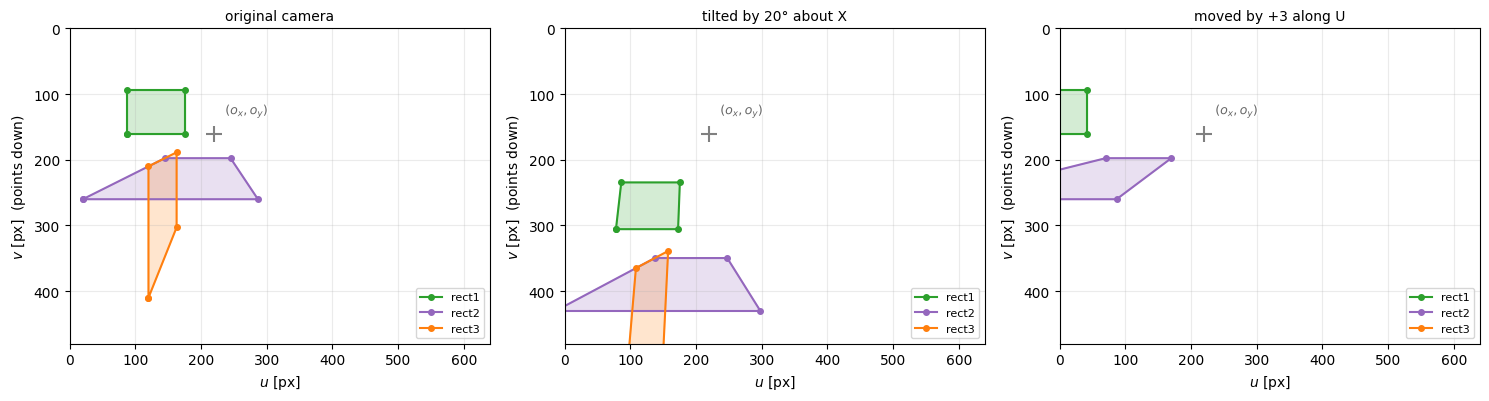

In [45]:
if ready(rect3, R_tilt, C_shift):
    fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, (title, Rx_, Cx_) in zip(axs, [("original camera", R, C), ("tilted by 20° about X", R_tilt, C), ("moved by +3 along U", R, C_shift)]):
        draw_image({"rect1": RECT1, "rect2": RECT2, "rect3": rect3}, project, K, Rx_, Cx_, title=title, ax=ax)
    plt.tight_layout(); plt.show()

**Answer**

1. Compare the images of the three rectangles. Which one stays a rectangle, which become trapezoids, and which edges remain parallel? Why? (Think of lines along $V$ — the viewing direction.). <br />
*After tilting the camera by 20 degrees, rect1 becomes a trapezoid, with its top and bottom edges remaining parallel because they are still parallel to the image plane. Rect2 also remains a trapezoid for the same reason. The other edges of rect1 are no longer parallel to the image plane. When translating the camera by +3 along U, We see rect2 isn't trapezoid anymore even though rect1 remains a rectangle.*

2. What happens to the image when the camera is turned about its $X$ axis? <br />
*Edges parallel to the X-axis remain parallel, while edges extending in other directions may converge due to changes in their depth relative to the camera.*

3. What happens when it is translated along $U$? We will have different distance between objects that are far away depth direction?<br />
*Translating the camera along U causes objects to shift horizontally in the image. The amount of displacement depends on their depth: closer objects shift more than distant ones.*

## Task 3.2 · Manipulating the pose of a 3D object (15 points)

The cube $\mathbf{V}$ (array `V`, eight vertices $\mathbf{x}_1,\dots,\mathbf{x}_8$) is projected as a tilted box. The vertices $\mathbf{x}_1,\dots,\mathbf{x}_4$ form the **front face**
(nearer to the camera), $\mathbf{x}_{i+4}$ lies behind $\mathbf{x}_i$ and the edge length is $L=3$.

**Task.** The camera (and its intrinsics) stay **fixed**. Find a *rigid* motion of the cube, $\mathbf{x}\mapsto\mathbf{R}_{\text{obj}}\mathbf{x}+\mathbf{t}_{\text{obj}}$ (no scaling, no mirroring), such that
* the front face is projected as an **axis-aligned square of side $120$ px** (which vertex lands on which corner of the square does not matter), and
* the cube stays in front of the camera, inside the image, with the front face **nearer** than the back face.

Implement `cube_pose(V, K, R, C, side_px)` returning `(R_obj, t_obj)`.

*Hints.* (i) Build an orthonormal frame from the cube's edges and align it with the camera axes. (ii) From the similar triangles of the pinhole model, the face side in pixels is $\tfrac{f}{s_x}\tfrac{L}{Z_0}$ — solve for the depth $Z_0$.
(iii) Place the face at depth $Z_0$.

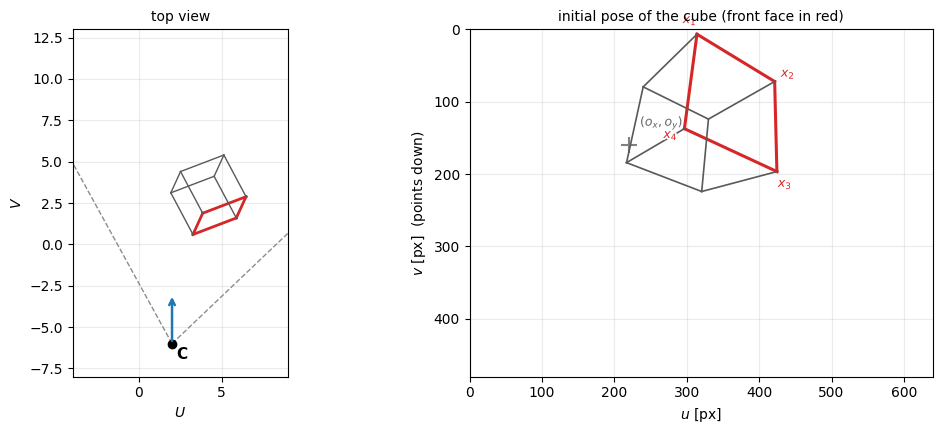

In [46]:
V = cube_vertices()                                 # the cube in its initial pose, shape (8, 3)
draw_scene({}, project, K, R, C, cube=V, title="initial pose of the cube (front face in red)")

In [47]:
#### START OF YOUR SOLUTION ####
"""

1. Describe your construction in a few sentences (which frame did you align with what, and how did you obtain the translation?).
First we constructed an orthonormal frame from cube's edges by taking edges coming out of the vertex 0 and normalizing them.
Then we aligned camera x, y and z axis with constructed frame. For translation we first compute depth from the camera with similar triangle principle and transform it in camera coordinate frame, because we are applying translation in the camera coordinate frame.
Then we add camera position and subtract the center of the front face.

2. **How many solutions are there?** Which freedoms of the cube's pose are fixed by the requirement, which are still free? Count the discrete choices and describe the continuous ones.
There are 4 ways of axis-aligning the front face of the cube depending on which vertices go where and there are infinitely many ways of translating our cube along U and V while staying in FOV of the camera.

3. Suppose the front-face centre must in addition lie **on the optical axis**. How many solutions remain?
Only 4.
"""


def cube_pose(V, K, R, C, side_px):
    """Return (R_obj, t_obj): a rigid motion that makes the front face a side_px x side_px axis-aligned square in the image."""
    v1 = (V[1] - V[0])
    v1 /= np.linalg.norm(v1)
    v2 = (V[4] - V[0])
    v2 /= np.linalg.norm(v2)
    v3 = (V[0] - V[3])
    v3 /= np.linalg.norm(v3)

    R_obj = np.stack([v1, v2, v3], axis=1).T

    # Center of the original front face
    center = (V[:4] @ R_obj.T).mean(axis=0)

    # Required depth for desired pixel size
    side_length = np.linalg.norm(V[1] - V[0])
    d = K[0, 0] * side_length / side_px

    # Desired front-face center in camera coordinates
    target_cam = np.array([0, 0, d])

    # Convert target into world coordinates
    target_world = C + R.T @ target_cam

    t_obj = target_world - center


    return (R_obj, t_obj)
#### END OF YOUR SOLUTION ####

In [48]:
pose = cube_pose(V, K, R, C, params.P3_TARGET_PX)
V_new = None if pose is None else rigid(V, *pose)
chk = Checker("Part 3 · Task 3.2 cube pose")
def _uv(Vn, Kx=K): return np.array([project(Kx, R, C, p) for p in Vn])
chk.test("R_obj is a proper rotation (orthonormal, det = +1): the motion is rigid", lambda: None if pose is None else bool(np.allclose(pose[0] @ pose[0].T, np.eye(3), atol=1e-8) and np.linalg.det(pose[0]) > 0))
chk.test("the cube is in front of the camera and inside the image", lambda: None if V_new is None else (lambda uv, z: bool(np.all(z > 0) and np.all((uv[:, 0] > 0) & (uv[:, 0] < W_img) & (uv[:, 1] > 0) & (uv[:, 1] < H_img))))(_uv(V_new), np.array([depth(R, C, p) for p in V_new])))
chk.test("the front face is nearer to the camera than the back face", lambda: None if V_new is None else bool(np.mean([depth(R, C, p) for p in V_new[:4]]) < np.mean([depth(R, C, p) for p in V_new[4:]])))
def _front_face(uv, side, centre=None, tol=0.25):
    """Is the projected front face an axis-aligned square of the given side (and centred)? Independent of which vertex label sits at which corner."""
    uv = np.asarray(uv, float); lo, hi = uv.min(axis=0), uv.max(axis=0)
    box = np.array([[lo[0], lo[1]], [hi[0], lo[1]], [hi[0], hi[1]], [lo[0], hi[1]]])           # the four corners of the bounding box
    near = np.argmin(np.linalg.norm(uv[:, None] - box[None], axis=2), axis=1)
    aligned = bool(len(set(near)) == 4 and np.allclose(uv, box[near], atol=tol))               # one projected vertex on each box corner
    w, hh = hi - lo
    ok = aligned and abs(w - side) < tol and abs(hh - side) < tol
    msg = f"bounding box {w:.2f} x {hh:.2f} px (wanted {side:g} x {side:g}); the corners are {'on' if aligned else 'NOT on'} the corners of the box"
    if centre is not None:
        c = uv.mean(axis=0); ok = ok and bool(np.allclose(c, centre, atol=tol)); msg += f"; centre ({c[0]:.1f}, {c[1]:.1f}), wanted ({centre[0]:g}, {centre[1]:g})"
    return bool(ok), msg
chk.test("the front face projects to an axis-aligned square of side 120 px",
         lambda: None if V_new is None else _front_face(_uv(V_new)[:4], 120.0),
         hint="align the cube's edges with the camera axes X (right) and Y (down); the depth Z0 of the face follows from side = (f/s_x) L / Z0")

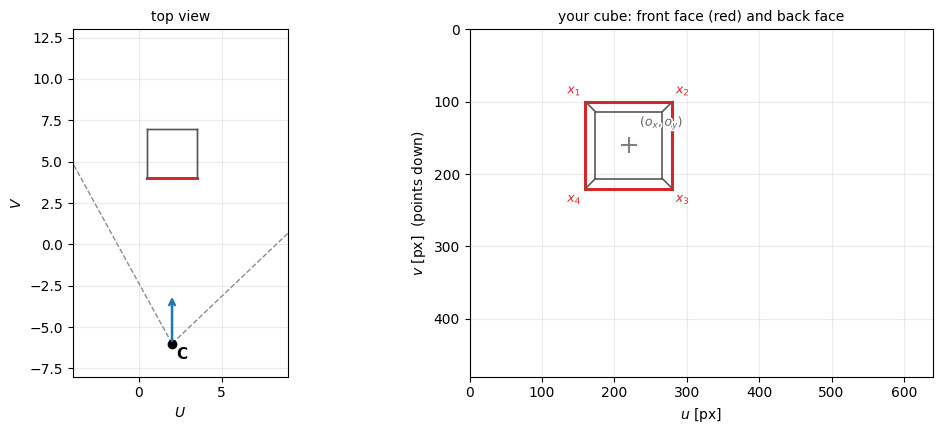

In [49]:
if ready(V_new):
    draw_scene({}, project, K, R, C, cube=V_new, title="your cube: front face (red) and back face")

**Answer**

1. Describe your construction in a few sentences (which frame did you align with what, and how did you obtain the translation?).<br />
  *First we constructed an orthonormal frame from cube's edges by taking edges coming out of the vertex 0 and normalizing them.* <br />
  *Then we aligned camera x, y and z axis with constructed frame. For translation we first compute depth from the camera with similar triangle principle and transform it in camera coordinate frame, because we are applying translation in the camera coordinate frame.*<br />
  *Then we add camera position and subtract the center of the front face.*

2. **How many solutions are there?** Which freedoms of the cube's pose are fixed by the requirement, which are still free? Count the discrete choices and describe the continuous ones.<br />
*There are 4 ways of axis-aligning the front face of the cube depending on which vertices go where and there are infinitely many ways of translating our cube along U and V while staying in FOV of the camera.*

3. Suppose the front-face centre must in addition lie **on the optical axis**. How many solutions remain?<br />
*Only 4 solutions remain, since we are fixing the cube position.*

## Task 3.3 · Manipulating the camera intrinsics (5 points)

Now keep the pose from Task 3.2 (`V_new`) and the camera pose $(\mathbf{R},\mathbf{C})$ fixed and change **only the intrinsics** $f$ (a length; $f=1$ at the start) and $(o_x,o_y)$ (the pixel size stays $s_x=s_y$). Choose them so that the front face is again an axis-aligned square which is

1. **doubled** (side $240$ px) and **centred in the image** (centre $(320,240)$, the middle of the $640\times480$ image),
2. **halved** (side $60$ px) and **centred in the image**,
3. **doubled and centred, for the moved cube** `V_shift` $=$ `V_new` $+\,(0.5,0,0)^\top$ (the cube shifted by $0.5$ units along the world $U$ axis; given).

Do **not** assume that $(o_x,o_y)$ is the image centre — it depends on where the square lands. Think about what $(o_x,o_y)$ does to the image: it shifts everything.

In [50]:
V_shift = None if V_new is None else V_new + np.array([0.5, 0.0, 0.0])     # (given) the cube of Task 3.2, moved by 0.5 along U

#### START OF YOUR SOLUTION ####
f_double, o_double = 2, (320, 240)
f_half,   o_half   = 0.5, (320, 240)
f_shift,  o_shift  = 2, (280, 240)
#### END OF YOUR SOLUTION ####

In [51]:
chk = Checker("Part 3 · Task 3.3 intrinsics")
def _front(fv, ov, V_cube):
    return np.array([project(intrinsics(fv, s_x, s_y, *ov), R, C, p) for p in V_cube[:4]])
def _square(fv, ov, side, V_cube):
    return _front_face(_front(fv, ov, V_cube), side, centre=(W_img / 2, H_img / 2), tol=0.6)
chk.test("doubled: 240 px square centred at (320, 240)", lambda: None if V_new is None or f_double is None else _square(f_double, o_double, 240.0, V_new),
         hint="side ∝ f; then shift with (o_x, o_y): project once with o = (0, 0) to see where the square lands; if the side is slightly off, Task 3.2 is not exact")
chk.test("halved: 60 px square centred at (320, 240)", lambda: None if V_new is None or f_half is None else _square(f_half, o_half, 60.0, V_new))
chk.test("moved cube V_shift (+0.5 along U), doubled: 240 px square centred at (320, 240)", lambda: None if V_shift is None or f_shift is None else _square(f_shift, o_shift, 240.0, V_shift),
         hint="the square of the moved cube lands elsewhere: the principal point of the unmoved cube does not work here")

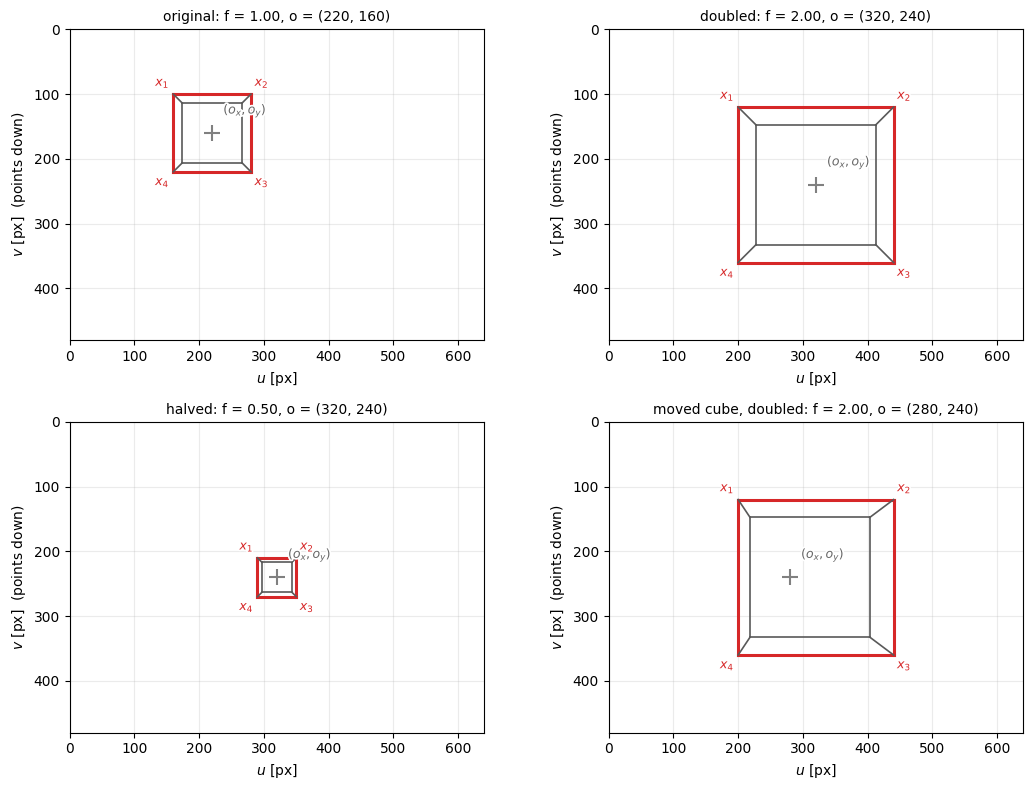

In [52]:
if ready(V_new, f_double, o_double, f_half, o_half, f_shift, o_shift):
    fig, axs = plt.subplots(2, 2, figsize=(11, 8))
    for ax, (title, fv, ov, Vc) in zip(axs.ravel(), [("original", f, o, V_new), ("doubled", f_double, o_double, V_new), ("halved", f_half, o_half, V_new), ("moved cube, doubled", f_shift, o_shift, V_shift)]):
        draw_image({}, project, intrinsics(fv, s_x, s_y, *ov), R, C, cube=Vc, title=f"{title}: f = {fv:.2f}, o = ({ov[0]:.0f}, {ov[1]:.0f})", ax=ax)
    plt.tight_layout(); plt.show()

**Answer**

1. Which $f$ and $(o_x,o_y)$ did you choose in each case, and why (derive them)? <br />
  *The projected size of an object is directly proportional to the focal lenght so doubling the focal length doubles the squares size, and halving the focal lenght halves its size.*<br />
  *The shiste cuba has its center at camera coordinates (0.5, 0, 10), with the doubled focal length its projected center is (40, 0)so we chose (280, 240) to center it*
2. Why is it wrong to simply take the image centre as $(o_x,o_y)$ in general? Give the formula for $(o_x,o_y)$ in terms of the camera coordinates $(X_c,Y_c,Z_c)^\top$ of the centre of the square.<br />
  *The center of the object does not necessarily lie on the optical axis*<br />
  $o_x=320-\frac{f}{s_x}\frac{X_c}{Z_c}$ <br />
  $o_y=240-\frac{f}{s_y}\frac{Y_c}{Z_c}$
3. What changes in the picture when you double $f$ with the camera fixed — and what change of the camera pose gives (for the front face of the cube) the same size? <br />
  *Doubling the focal length makes objects appear larger. Moving the camera closer (half of the original distance) would make the objects appear the same size as with double the focal lenght but it would also change the perspective of the scene*

---
### Summary of the checks

In [53]:
progress()

checks,passed,failed,not implemented
Part 3 · Task 3.1a project,5,0,0
Part 3 · Task 3.1b rect3,4,0,0
Part 3 · Task 3.1c moving the camera,3,0,0
Part 3 · Task 3.2 cube pose,4,0,0
Part 3 · Task 3.3 intrinsics,3,0,0


{'Part 3 · Task 3.1a project': {'a point on the optical axis lands on the principal point': 'pass',
  'project(p_1), p = [2.  3.  1.5]': 'pass',
  'project(p_2), p = [1. 1. 2.]': 'pass',
  'project(p_3), p = [3.5 4.  0.5]': 'pass',
  'project(p_4), p = [-1.  6.  0.]': 'pass'},
 'Part 3 · Task 3.1b rect3': {'rect3 has four corners with the same U (a wall parallel to the V-W plane)': 'pass',
  'its extent is 3 along V and 2 along W': 'pass',
  'it is a rectangle (right angles at the corners)': 'pass',
  'all four corners are in front of the camera and inside the image': 'pass'},
 'Part 3 · Task 3.1c moving the camera': {'R_tilt is a rotation matrix': 'pass',
  "R_tilt R^T = R_x(20°)^T  (body rotated by Q = R_x(20°); R' = Q^T R)": 'pass',
  'C_shift': 'pass'},
 'Part 3 · Task 3.2 cube pose': {'R_obj is a proper rotation (orthonormal, det = +1): the motion is rigid': 'pass',
  'the cube is in front of the camera and inside the image': 'pass',
  'the front face is nearer to the camera than 